In this project, we will analyze a provided dataset containing various variables related to the context of higher education students. All variables serve as features, while the target variable represents the students' status: graduated, dropped out, or currently enrolled. To this end, we will begin by gaining an overview of the dataset, followed by cleaning, organizing, and analyzing it, identifying potential correlations between variables, and finally applying PCA.

In [1]:
from sklearn.preprocessing import RobustScaler, StandardScaler, MinMaxScaler,Normalizer,LabelEncoder
import sklearn.preprocessing as preproc
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from matplotlib import pyplot
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
%matplotlib inline
!pip install mglearn
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
import pandas as pd
from scipy import stats
from scipy.stats import kurtosis
sns.set()
sns.set(color_codes=True)
pd.set_option("display.max_columns", None)

In [2]:
df=pd.read_csv("student_dataV2.csv")
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1.0,17.0,5.0,171.0,1,1,122.0,1.0,19,12.0,5.0,9.0,127.3,1.0,0,0.0,1.0,1,0,20.0,0.0,0.0,0,0,0,0.000000,0,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1.0,15.0,1.0,9254.0,1,1,160.0,1.0,1,3.0,3.0,3.0,142.5,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,6,6,14.000000,0,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1.0,1.0,5.0,9070.0,1,1,122.0,1.0,37,37.0,9.0,9.0,124.8,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,0,0,0.000000,0,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1.0,17.0,2.0,9773.0,1,1,122.0,1.0,38,37.0,5.0,3.0,119.6,1.0,0,0.0,1.0,0,0,20.0,0.0,0.0,6,8,6,13.428571,0,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2.0,39.0,1.0,8014.0,0,1,100.0,1.0,37,38.0,9.0,9.0,141.5,0.0,0,0.0,1.0,0,0,45.0,0.0,0.0,6,9,5,12.333333,0,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1.0,1.0,6.0,9773.0,1,1,125.0,1.0,1,1.0,5.0,4.0,122.2,0.0,0,0.0,1.0,1,0,19.0,0.0,0.0,6,7,5,13.600000,0,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate
4420,1.0,1.0,2.0,9773.0,1,1,120.0,105.0,1,1.0,9.0,9.0,119.0,1.0,0,1.0,0.0,0,0,18.0,1.0,0.0,6,6,6,12.000000,0,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout
4421,1.0,1.0,1.0,9500.0,1,1,154.0,1.0,37,37.0,9.0,9.0,149.5,1.0,0,0.0,1.0,0,1,30.0,0.0,0.0,7,8,7,14.912500,0,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout
4422,1.0,1.0,1.0,9147.0,1,1,180.0,1.0,37,37.0,7.0,4.0,153.8,1.0,0,0.0,1.0,0,1,20.0,0.0,0.0,5,5,5,13.800000,0,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate


Regarding the structure of the dataframe, we can see that it consists of 37 columns and 4,424 rows, covering everything from the students' personal details to their grades or credits across various semesters, as well as elements related to macroeconomics.

In [3]:
df.info() 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4423 non-null   float64
 1   Application mode                                4423 non-null   float64
 2   Application order                               4423 non-null   float64
 3   Course                                          4421 non-null   float64
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4420 non-null   float64
 7   Nacionality                                     4423 non-null   float64
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

When looking at the data categories, there are variables that appear as categorical, even though the data dictionary indicates they should be numeric,this shows that there are likely null values that the program has not recognized as such. In some variables it has mising or null data, because there is less columsin the folowin features, Application mode , Application order,Course,Previous qualification (grade),Father's qualification,Mother's occupation,Father's occupation,Admission grade,Debtor,Tuition fees up to date ,Age at enrollment, International, Curricular units 1st sem (grade),Curricular units 2nd sem (enrolled) , Curricular units 2nd sem (grade)

In [4]:
df.isnull().sum()

Marital status                                    1
Application mode                                  1
Application order                                 1
Course                                            3
Daytime/evening attendance                        0
Previous qualification                            0
Previous qualification (grade)                    4
Nacionality                                       1
Mother's qualification                            0
Father's qualification                            1
Mother's occupation                               1
Father's occupation                               1
Admission grade                                   2
Displaced                                         1
Educational special needs                         0
Debtor                                            1
Tuition fees up to date                           2
Gender                                            0
Scholarship holder                                0
Age at enrol

In [5]:
df.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4423.000000,4423.000000,4423.000000,4421.000000,4424.000000,4424.000000,4420.000000,4423.000000,4424.000000,4423.000000,4423.000000,4423.000000,4422.000000,4423.000000,4424.000000,4423.000000,4422.000000,4424.000000,4424.000000,4422.000000,4423.000000,4423.000000,4424.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4423.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178612,18.663351,1.727560,8856.331147,0.890823,4.577758,132.621561,1.873389,19.561935,22.271987,10.961338,11.033914,126.988512,0.548270,0.011528,0.113724,0.880823,0.351718,0.248418,23.266848,0.024870,0.708795,6.270570,8.299051,4.706600,10.640100,0.137658,0.541817,6.231743,8.063291,4.435805,10.229941,0.150316,11.566139,1.228029,0.001969
std,0.605809,17.482509,1.313802,2064.221611,0.311897,10.216592,13.189209,6.915283,15.603186,15.343244,26.421223,25.265675,14.476775,0.497721,0.106760,0.317511,0.324033,0.477560,0.432144,7.589042,0.155746,2.359433,2.480178,4.179106,3.094238,4.843973,0.690880,1.918546,2.196038,3.947951,3.014764,5.211367,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,33.000000,0.000000,1.000000,95.000000,1.000000,1.000000,1.000000,0.000000,0.000000,95.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,9085.000000,1.000000,1.000000,125.000000,1.000000,2.000000,3.000000,4.000000,4.000000,117.900000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,19.000000,0.000000,0.000000,5.000000,6.000000,3.000000,11.000000,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,17.000000,1.000000,9238.000000,1.000000,1.000000,133.100000,1.000000,19.000000,19.000000,5.000000,7.000000,126.100000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,20.000000,0.000000,0.000000,6.000000,8.000000,5.000000,12.285714,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,39.000000,2.000000,9556.000000,1.000000,1.000000,140.000000,1.000000,37.000000,37.000000,9.000000,9.000000,134.800000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,25.000000,0.000000,0.000000,7.000000,10.000000,6.000000,13.399000,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,57.000000,9.000000,9991.000000,1.000000,43.000000,190.000000,109.000000,44.000000,44.000000,194.000000,195.000000,190.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,70.000000,1.000000,20.000000,26.000000,45.000000,26.000000,18.875000,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


Although many columns appear numerical, they actually represent categorical variables that have been numerically encoded; consequently, metrics like the mean are, quite obviously, meaningless. There are, however, other aspects worth examining—for instance, the range or the averages. Take, for example, age at enrollment: the average is around 23.3 years—indicating a relatively young demographic—with a standard deviation of seven.

In [6]:
df.dtypes

Marital status                                    float64
Application mode                                  float64
Application order                                 float64
Course                                            float64
Daytime/evening attendance                          int64
Previous qualification                              int64
Previous qualification (grade)                    float64
Nacionality                                       float64
Mother's qualification                              int64
Father's qualification                            float64
Mother's occupation                               float64
Father's occupation                               float64
Admission grade                                   float64
Displaced                                         float64
Educational special needs                           int64
Debtor                                            float64
Tuition fees up to date                           float64
Gender        

So, in the data diccionary we see that some of the variables have dirty or mising data that is not reflected in the is null. Fore exsample in marital status the data should have a numerical descriptor from 1 to 6 indicate the diferent categories, but it says object, so even if says that is not any null, something is wrong. Nacionalyty as well even if it sais 0 null, it says that is an object, when in the data diccionary says that the categoris are encode in integer numbers. These kind of problemes whit a wrong type of feature in the answer of the sistem and in the data diccionary are presents in numerous variables. Is necesary to check all of the unique values and compare the answer with the espected values acording to the data diccionary.

In [7]:
df['Marital status'].unique() 

array([ 1.,  2.,  4., nan,  3.,  5.,  6.])

Integer numbers from 1 to 6 ok. just "?" is wrong 

In [8]:
mvf=['?']
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [9]:
df['Marital status'].unique()

array([ 1.,  2.,  4., nan,  3.,  5.,  6.])

In [10]:
df['Application mode'].unique()

array([17., 15.,  1., 39., 18., 53., 44., 51., 43.,  7., 42., 16.,  5.,
        2., 10., 57., 26., 27., nan])

Integer numbers corresponding to the specific ones stipuled in the data diccionary.The nan is allredy show as 1 null before

In [11]:
df['Application order'].unique() 

array([ 5.,  1.,  2.,  4.,  3.,  6., nan,  9.,  0.])

Integer numbers from 0 to 9 ok. The nan is allredy show as 1 null before

In [12]:
df['Course'].unique()

array([ 171., 9254., 9070., 9773., 8014., 9991., 9500., 9238., 9670.,
       9853., 9085., 9130., 9556., 9147., 9003.,   33., 9119.,   nan])

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 33 , 171 , 8014, 9003 , 9070, 9085 , 9119 , 9130 ,9147 ,9238,9254 ,9500,9556 ,9670 ,9773 ,9853,9991.  Also the nan is allredy show as 3 null before.

In [13]:
df['Daytime/evening attendance'].unique() #Everithing good here

array([1, 0], dtype=int64)

In [14]:
df['Previous qualification'].unique()

array([ 1, 19, 42, 39, 10,  3, 40,  2,  4, 12, 43, 15,  6,  9, 38,  5, 14],
      dtype=int64)

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 1,2,3,4,5,6,9,10,12,14,15,19,38,39,40,42,43. All good here

In [15]:
df['Previous qualification (grade)'].unique()

array([122. , 160. , 100. , 133.1, 142. , 119. , 137. , 138. , 139. ,
       136. , 133. , 110. , 149. , 127. , 135. , 140. , 125. , 126. ,
       151. , 115. , 150. , 143. , 130. , 120. , 103. , 154. , 132. ,
       167. , 129. , 141. , 116. , 148. , 118. , 106. , 121. , 114. ,
       124. ,   nan, 123. , 113. , 111. , 131. , 158. , 146. , 117. ,
       153. , 178. ,  99. , 134. , 128. , 170. , 155. , 145. , 152. ,
       112. , 107. , 156. , 188. ,  96. , 161. , 166. , 147. , 144. ,
       102. , 101. , 180. , 172. , 105. , 108. , 165. , 190. , 162. ,
       164. , 163. , 159. , 117.4, 175. , 133.8, 176. , 168. , 139.3,
        97. , 157. , 140.8, 184.4, 148.9, 109. , 174. , 182. , 138.6,
        95. , 154.4, 163.3, 145.7, 123.9, 124.4, 169. , 177. , 138.7,
       119.1, 118.9, 126.6])

In [16]:
Previous_qualification_grade_min=df['Previous qualification (grade)'].min()
print(Previous_qualification_grade_min)

95.0


In [17]:
Previous_qualification_grade_max=df['Previous qualification (grade)'].max()
print(Previous_qualification_grade_max)

190.0


The numbers are continuos and bethwen 95 and 190, the range has to be bethwen 0 and 200 so is good. Also the nan is allredy show as 4 null before.

In [18]:
df['Nacionality'].unique()

array([  1.,  62.,   6.,  41.,  26., 103.,  13.,  25.,  21., 101.,  11.,
        22.,  32., 100.,  24., 109.,   2., 108., 105.,  14.,  nan,  17.])

Integer numbers corresponding to the specific ones stipuled in the data diccionary: 1, 2, 6, 11, 13, 14, 17, 21, 22, 24, 25, 26, 32, 41, 62, 100, 101, 103, 105, 108, 109  ok. just "?" is wrong

In [19]:
mvf=['?']
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [20]:
df['Nacionality'].unique()

array([  1.,  62.,   6.,  41.,  26., 103.,  13.,  25.,  21., 101.,  11.,
        22.,  32., 100.,  24., 109.,   2., 108., 105.,  14.,  nan,  17.])

In [21]:
df["Mother's qualification"].unique() 

array([19,  1, 37, 38,  3,  4, 42,  2, 34, 12, 40,  9,  5, 39, 11, 41, 30,
       14, 35, 36,  6, 10, 29, 43, 18, 22, 27, 26, 44], dtype=int64)

The type of quotation marks used—specifically the distinction between double and single quotes—caused confusion within the system regarding the variable name being sought, due to the apostrophe in "mothers and fathers"; I therefore switched to double quotes to avoid this issue.

In [22]:
df["Father's qualification"].unique() 

array([12.,  3., 37., 38.,  1., 19.,  5.,  4., 34.,  2., 39., 11.,  9.,
       nan, 36., 26., 40., 14., 20., 35., 41., 22., 13., 29., 43., 18.,
       42., 10.,  6., 30., 25., 44., 33., 27., 31.])

In Mother's and Father's qualification is ok, integer numbers corresponding to the specific ones stipuled in the data diccionary:1, 2, 3, 4, 5, 6, 9, 10, 11, 12, 14, 18, 19, 22, 26, 27, 29, 30, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, all good. In  Father's qualification there is one null adecuade detected.

In [23]:
df["Mother's occupation"].unique() 

array([  5.,   3.,   9.,   7.,   4.,   1., 125.,   0.,   6.,   2.,  90.,
         8.,  nan, 141., 175.,  99., 191., 151., 194., 192., 132., 152.,
       134.,  10., 143., 123., 173., 193., 122., 144., 131., 171., 153.])

In Mother's occupation is ok, integer numbers corresponding to the specific ones stipuled in the data diccionary:0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 90, 99, 122, 123, 125, 131, 132, 134, 141, 143, 144, 151, 152, 153, 171, 173, 175, 191, 192, 193, 194, all good. The null is alrredy marked

In [24]:
df["Father's occupation"].unique() 

array([  9.,   3.,   7.,  10.,   5.,   8.,   4.,   1.,   2., 124.,   6.,
         0.,  90., 175., 121.,  99., 144., 195., 192., 161., 193., 151.,
       182., 132., 131., 194., 163., 135., 143., 171., 103., 172., 152.,
       183., 122., 102., 181., 134., 123., 112., 153., 174., 141., 114.,
        nan, 101., 154.])

In Father's occupation integer numbers corresponding to the specific ones stipuled in the data diccionary:0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 90, 99, 101, 102, 103, 112, 114, 121, 122, 123, 124, 131, 132, 134, 135, 141, 143, 144, 151, 152, 153, 154, 161, 163, 171, 172, 174, 175, 181, 182, 183, 192, 193, 194, 195, but the category in marked as object, because apart of the correct marked null (nan), there is a "FIVE" that have to be corrected

In [25]:
df["Father's occupation"]=df["Father's occupation"].replace("Five","5")

Initially, I replaced the word "five" with the number 5, but then I realized that a specific option had been clearly indicated there; furthermore, there were several similar errors within the target category, so, to maintain consistency, I replaced the word "five" with the number 5.

In [26]:
df["Father's occupation"].unique()  

array([  9.,   3.,   7.,  10.,   5.,   8.,   4.,   1.,   2., 124.,   6.,
         0.,  90., 175., 121.,  99., 144., 195., 192., 161., 193., 151.,
       182., 132., 131., 194., 163., 135., 143., 171., 103., 172., 152.,
       183., 122., 102., 181., 134., 123., 112., 153., 174., 141., 114.,
        nan, 101., 154.])

In [27]:
df["Admission grade"].unique() 

array([127.3, 142.5, 124.8, 119.6, 141.5, 114.8, 128.4, 113.1, 129.3,
       123. , 130.6, 119.3, 130.2, 111.8, 137.1, 120.7, 137.4, 136.3,
       124.6, 120.3, 121.8, 125.5, 114.9, 123.9, 157. , 116.4, 131. ,
       122.1, 118.8, 150. , 130. , 138.8, 134.5, 131.4, 102.5, 128.8,
       122.9, 113.9, 120. , 121.1, 120.4, 100.6, 121.4, 109.7, 134.1,
       127.6, 132.4, 133.4, 126.1, 113.5, 121.3, 159.3, 129.1, 155.3,
       139.8, 115.2, 131.9, 126. , 120.9, 128.2, 120.1, 100. , 134. ,
       130.8, 135.8, 111.7, 132.9, 115.5, 106. , 117. , 110.2, 155.7,
       180.4, 110. , 161. , 117.6, 128.7, 112.2, 100.8, 105. , 114. ,
       137. , 124.9, 134.3, 111.5, 160. , 117.4, 122.2, 118.2, 106.7,
       108.2, 107. , 136.1, 115.3, 140.4, 113.4, 118.6, 122.3, 127.9,
       117.1, 145.3, 122.6, 128. , 123.7, 131.7, 133.2, 109.3, 113. ,
       157.9, 112.1, 174.7, 110.1,  99.7, 121. , 119.1, 124.7, 117.2,
       131.5, 121.7, 123.4, 132.8, 108.7, 138.1, 126.5, 127.4, 123.6,
       122. , 125.8,

In [28]:
Admission_grade_min=df['Admission grade'].min()
print(Admission_grade_min)

95.0


In [29]:
Admission_grade_max=df['Admission grade'].max()
print(Admission_grade_max)

190.0


The numbers are continuos and bethwen 95 and 190, the range has to be bethwen 0 and 200 so is good. Also the nan is allredy show as 2 null before.

In [30]:
df["Displaced"].unique()  # the first time i runed the cel it was a ?, vut after it get fixed wen I marked that as nan in other feature

array([ 1.,  0., nan])

In [31]:
df["Educational special needs"].unique() #ok

array([0, 1], dtype=int64)

In [32]:
df["Debtor"].unique() #ok

array([ 0.,  1., nan])

In [33]:
df["Tuition fees up to date"].unique() #ok, nan fixed by code before

array([ 1.,  0., nan])

In [34]:
df["Gender"].unique() #ok

array([1, 0], dtype=int64)

In [35]:
df["Scholarship holder"].unique() #ok

array([0, 1], dtype=int64)

In [36]:
df["Age at enrollment"].unique() 

array([20., 19., 45., 50., 18., 22., 21., 34., 37., 43., 55., 39., 29.,
       24., 27., 23., 26., 33., 35., 25., 44., 36., 47., 28., 38., nan,
       30., 31., 32., 40., 42., 48., 49., 46., 41., 70., 60., 53., 51.,
       52., 54., 61., 58., 59., 17., 57., 62.])

In Age at enrollmen integer numbers, but the category in marked as object, because apart of the correct marked null (nan), there is a "UnKnown" that has to be corrected. 

In [37]:
mvf=['UnKnown'] 
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [38]:
df["International"].unique() #ok with correct nan

array([ 0.,  1., nan])

In [39]:
df["Curricular units 1st sem (credited)"].unique() 

array([ 0.,  2.,  3.,  6.,  7., 13.,  4.,  1.,  5., 19., 11.,  8., 10.,
        9., 15., 12., 14., 18., 17., 16., 20., nan])

Ok integer numbers, but the category is marked as object, because there is a "Na" that has to be corrected. 

In [40]:
mvf=['Na'] 
df=pd.read_csv("student_dataV2.csv",na_values=mvf)

In [41]:
df["Curricular units 1st sem (enrolled)"].unique() #ok

array([ 0,  6,  5,  7,  8,  1, 12, 10, 18,  9, 21,  3, 17, 16, 11, 14, 13,
        2,  4, 15, 19, 23, 26], dtype=int64)

In [42]:
df["Curricular units 1st sem (evaluations)"].unique() #ok

array([ 0,  6,  8,  9, 10,  5,  7, 14, 12, 15, 13, 11,  1, 17, 18, 19, 21,
        4, 16,  3, 24,  2, 22, 45, 20, 26, 29, 36, 32, 23, 27, 31, 28, 25,
       33], dtype=int64)

In [43]:
df["Curricular units 1st sem (approved)"].unique() #ok

array([ 0,  6,  5,  7,  4,  1,  3,  2,  8, 18, 10,  9, 21, 11, 13, 12, 16,
       14, 17, 19, 15, 20, 26], dtype=int64)

In [44]:
df["Curricular units 1st sem (grade)"].unique() 

array([ 0.        , 14.        , 13.42857143, 12.33333333, 11.85714286,
       13.3       , 13.875     , 11.4       , 13.21428571, 10.57142857,
       13.25      , 13.2       , 12.        , 13.30625   , 12.5       ,
       11.66666667, 11.4375    , 12.85714286, 13.375     , 13.29666667,
       11.6       , 11.375     , 12.66666667, 12.93333333, 12.83333333,
       11.33333333, 12.4       , 10.        , 11.        , 12.75      ,
       14.8       , 13.928     , 13.        , 11.5       , 13.51666667,
       13.66666667, 11.83333333, 14.71428571, 10.6       , 13.04444444,
       14.935     , 13.13333333, 11.9       , 12.57142857, 11.2       ,
       11.975     , 10.33333333, 10.5       , 14.84285714, 12.2       ,
       12.16666667, 13.08      , 10.66666667, 11.875     , 13.75      ,
       14.2       , 11.96      , 12.875     , 14.63157895, 13.26666667,
       13.85714286, 13.4       , 12.51666667, 11.61666667, 13.14285714,
       12.6       , 10.8       , 12.8       , 14.16666667, 12.1 

Dice que deberian ser inter numeros, pero es decimal #debe haber alguna manera de sacarle desimales. 

In [45]:
Curricular_units_1st_sem_min=df['Curricular units 1st sem (grade)'].min()
print(Curricular_units_1st_sem_min)

0.0


In [46]:
Curricular_units_1st_sem_max=df['Curricular units 1st sem (grade)'].max() 
print(Curricular_units_1st_sem_max)

18.875


The grades are bethen 0 and 20 as the data diccionary indicate and the null is marked

In [47]:
df["Curricular units 1st sem (without evaluations)"].unique() #ok

array([ 0,  1,  2,  4,  3,  6, 12, 10,  7,  5,  8], dtype=int64)

In [48]:
df["Curricular units 2nd sem (credited)"].unique() #ok

array([ 0,  1,  2,  5,  7,  4, 10,  3, 13,  9,  6, 11, 12,  8, 14, 15, 16,
       18, 19], dtype=int64)

In [49]:
df["Curricular units 2nd sem (enrolled)"].unique() #ok correct nan

array([ 0.,  6.,  5.,  8.,  7., 11., 12.,  9., 13., 19.,  3., 10.,  4.,
       nan, 17.,  2.,  1., 14., 15., 16., 23., 18., 21.])

In [50]:
df["Curricular units 2nd sem (evaluations)"].unique() #ok

array([ 0,  6, 10, 17,  8,  5,  7, 14,  9, 12, 11, 13, 19,  3, 15, 16,  4,
       18,  2, 21,  1, 26, 27, 22, 20, 24, 28, 23, 25, 33], dtype=int64)

In [51]:
df["Curricular units 2nd sem (approved)"].unique() #ok

array([ 0,  6,  5,  8,  2,  7,  4,  1,  3, 10, 13, 11, 19,  9, 12, 17, 14,
       20, 16, 18], dtype=int64)

In [52]:
df["Curricular units 2nd sem (grade)"].unique() 

array([ 0.        , 13.66666667, 12.4       , 13.        , 11.5       ,
       14.345     , 14.14285714, 13.5       , 14.2       , 13.21428571,
       11.        , 12.        , 14.545     , 12.25      , 11.425     ,
       12.85714286, 12.28571429, 14.11428571, 13.28571429, 12.33333333,
       13.71666667, 10.57142857, 13.4       , 14.375     , 13.42857143,
       10.        , 11.6       , 15.8       , 14.34285714, 13.8       ,
       14.33333333, 13.2       , 13.77142857, 12.83333333, 14.16666667,
       11.83333333, 13.595     , 12.9       , 14.935     , 12.22142857,
       12.42857143, 10.75      , 10.8       , 13.75      , 10.85714286,
       13.33333333, 15.05555556, 11.66666667, 12.2       , 13.3       ,
       11.33333333, 13.08      , 11.2       , 13.25      , 14.47777778,
       14.23076923, 12.27272727, 12.3       , 15.        , 12.8       ,
       12.57142857, 12.51666667, 10.66666667, 11.4       , 14.        ,
       11.25      , 13.77777778, 15.01111111, 13.74285714, 14.6 

In [53]:
Curricular_units_2nd_sem_min=df['Curricular units 2nd sem (grade)'].min()
print(Curricular_units_2nd_sem_min)

0.0


In [54]:
Curricular_units_2nd_sem_max=df['Curricular units 2nd sem (grade)'].max()
print(Curricular_units_2nd_sem_max)

18.571428571428573


Ok bethwen 0 an 20, null marked. Same as Curricular units 1st sem (grade) is continuos marked in data diccionary as integral number

In [55]:
df["Curricular units 2nd sem (without evaluations)"].unique() #ok

array([ 0,  5,  2,  1,  3,  6,  4, 12,  7,  8], dtype=int64)

In [56]:
df=df.astype({})

In [57]:
df["Unemployment rate"].unique() #ok continuo

array([10.8, 13.9,  9.4, 16.2, 15.5,  8.9, 12.7, 11.1,  7.6, 12.4])

In [58]:
df["Inflation rate"].unique() #ok continuo, "-" is deflacion

array([ 1.4, -0.3, -0.8,  0.3,  2.8,  3.7,  0.6,  2.6,  0.5])

In [59]:
df["GDP"].unique() #ok continuo,is GDP rate in reality aparently 

array([ 1.74,  0.79, -3.12, -0.92, -4.06,  3.51, -1.7 ,  2.02,  0.32,
        1.79])

In [60]:
df["Target"].unique() 

array(['Dropout', 'Graduate', 'Enrolled'], dtype=object)

There are clare null valus not registered, but because is evident what category are they tying to show ill will keep it, changing the speling but mainteining the meaning. To keep the same criteria in all the data, Ill do the same with "five" in Father's occupation.

In [61]:
df["Target"]=df["Target"].replace("Grad","Graduate")

In [62]:
df["Target"]=df["Target"].replace("graduate","Graduate")

In [63]:
df["Target"]=df["Target"].replace("Drop","Dropout")

In [64]:
df["Target"]=df["Target"].replace("dropout","Dropout")

In [65]:
df["Father's occupation"]=df["Father's occupation"].replace("Five","5")

In [66]:
df["Father's occupation"].unique()  

array([  9.,   3.,   7.,  10.,   5.,   8.,   4.,   1.,   2., 124.,   6.,
         0.,  90., 175., 121.,  99., 144., 195., 192., 161., 193., 151.,
       182., 132., 131., 194., 163., 135., 143., 171., 103., 172., 152.,
       183., 122., 102., 181., 134., 123., 112., 153., 174., 141., 114.,
        nan, 101., 154.])

Data is clean so Ill go to start analycing, i have tried using pariplot but the sistem understand numbers of codification as values, so ill change it.

I need to understand the distribution of each one to se the best way of doing it. The order of aplication is not really a numerical feature, but because is ordinal in terms of numerical position (preference 0 to preference 10) could be usefull see relations whith this positions represented close by numbers.  

In [67]:
Family_Context={"Father's occupation", "Mother's qualification","Father's qualification","Mother's occupation","Father's occupation"} 

In [68]:
Enroll_Numerical_Features=["Application order","Previous qualification (grade)", "Admission grade", "Age at enrollment"]

In [69]:
First_Semester_Numerical_Features=["Curricular units 1st sem (credited)" , "Curricular units 1st sem (enrolled)","Curricular units 1st sem (evaluations)","Curricular units 1st sem (approved)","Curricular units 1st sem (without evaluations)","Curricular units 1st sem (grade)"]

In [70]:
Second_Semester_Numerical_Features=["Curricular units 2nd sem (credited)","Curricular units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)","Curricular units 2nd sem (approved)", "Curricular units 2nd sem (without evaluations)","Curricular units 2nd sem (grade)"]

In [71]:
Context_Numerical_Features=["Unemployment rate","Inflation rate","GDP"]

I group the variables by type to simplify the analysis, but ultimately, I don’t think it makes sense to create specific charts for every single type—only for some of them.

In [72]:
print(df.columns.tolist())

['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


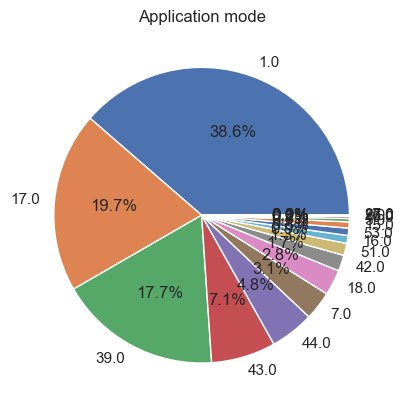

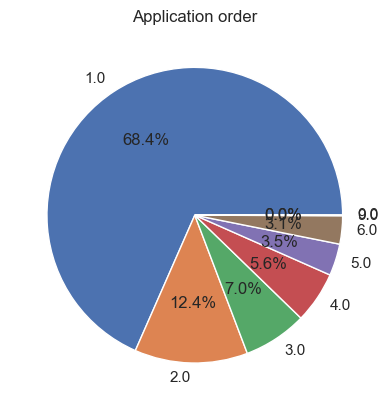

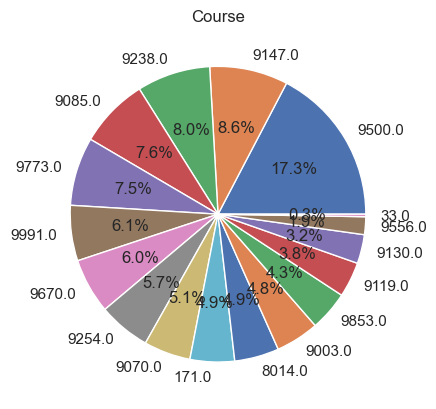

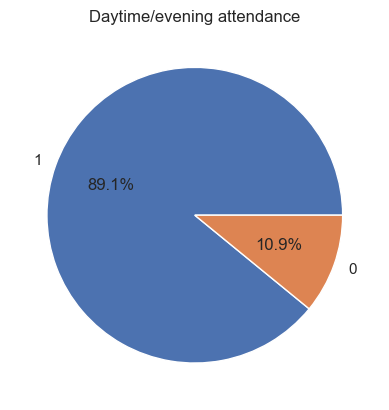

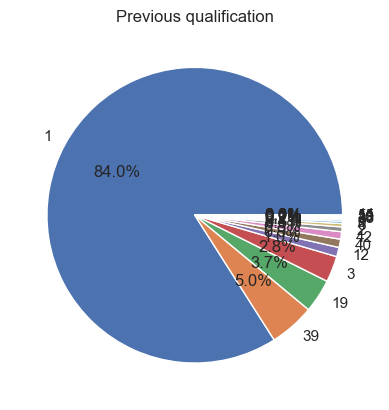

In [73]:
cols = ['Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification']
for c in cols:
        df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
        plt.show()

Regarding the application method, we observe that more than a third applied during the first general phase, followed by 19.7% during the second general phase; in third place, with 17.7%, was a special application process for those over 23 and under 42, with other application methods accounting for smaller percentages.

Regarding the order of application, we observe that the vast majority of students selected the course in question as their top priority—specifically 68.4% of them. It is listed as the second priority by 12.4% of students, followed by a steady decline (7% for the third priority, and so on). Consequently, it appears that most students are enrolled in the course they chose as their primary preference, which could potentially indicate a high level of motivation and a personal commitment in this regard.

Regarding the courses, we observe a fairly even distribution. While the tourism course accounts for 17% of the students, the other courses generally fall within the 4% to 8% range.
Respecto al horario, la inmensa mayoría de los estudiantes, correspondiente a un 89.1%, atiende de día, solo un 10.9 de noche.

Regarding the qualification prior to entering the course, the vast majority have completed secondary education, with 84% falling into this category.

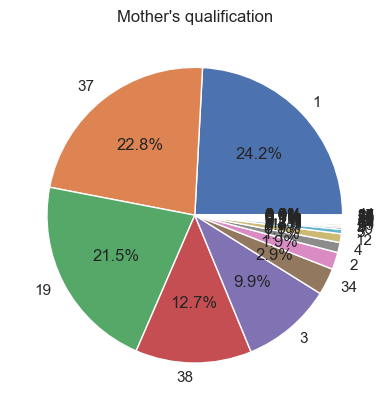

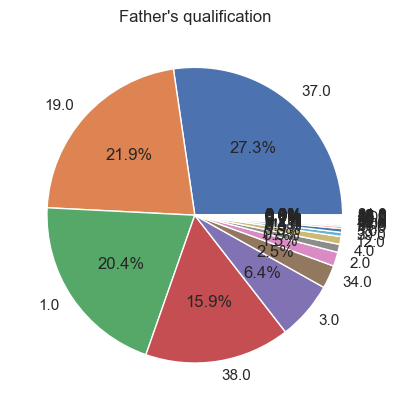

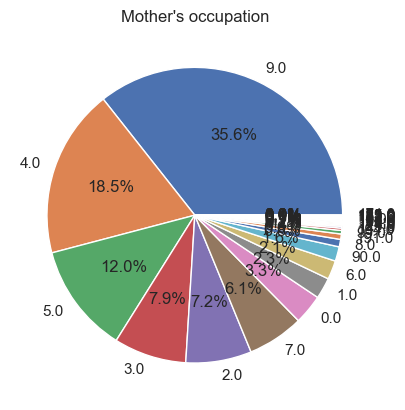

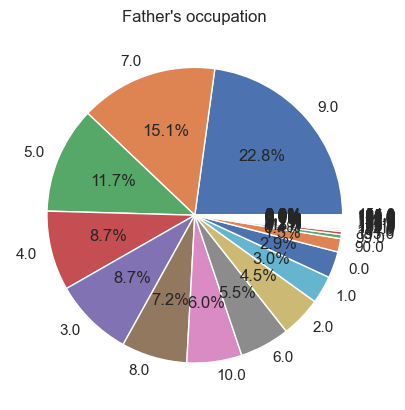

In [74]:
cols = ["Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
for c in cols:
        df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
        plt.show()

Regarding the education of the students' mothers, although 24.2% completed higher education, it is striking that the following categories, with a combined percentage higher than this, at around 45%,represent different levels of basic education. This indicates that these students are reaching higher educational levels than their mothers were able to access. Regarding the maximum educational level reached by the students' fathers, the level tends to be slightly lower than that of the mothers, as the main majorities are basic education and completed secondary education accounts for only 20.4%, becoming the third majority, and with a slightly higher total level of those who only reached basic education, corresponding to around 60%.

Regarding the occupation of the students' mothers, the unskilled workers category represents 35.6%, followed by administrative staff at 18.5% and personal services at 12%, with other categories to a lesser extent, occupations that are likely related to their relatively low educational level. Regarding the occupation of the fathers, 22.8% are also in the unskilled worker category, followed by 15.1% in skilled workers in industrial, construction and craftsmen, and 11.7% in personal service. We see that regarding the fathers, despite a lower educational level, there is labor insertion with higher skill levels, which may be due to various gender factors, such as traditional caregiving versus provider roles associated with each gender.

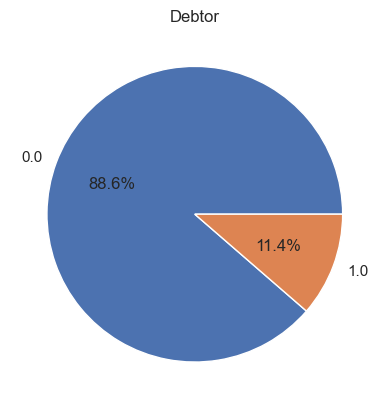

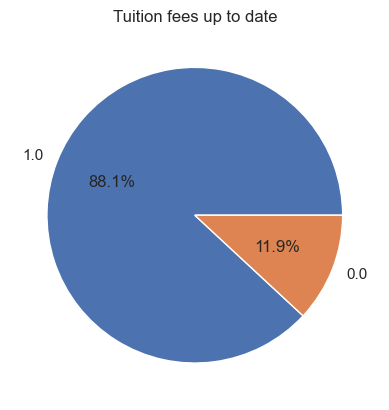

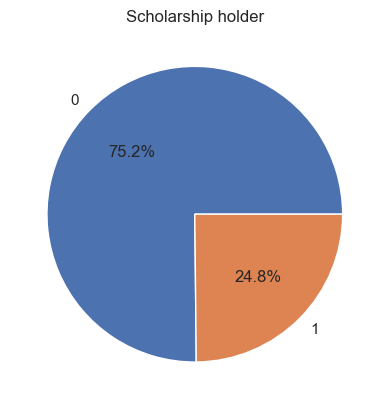

In [106]:
cols = ['Debtor', 'Tuition fees up to date', 'Scholarship holder']
for c in cols:
        df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
        plt.show()

Regarding the aspects of student education payments, 88.6% of students are not in debt to the institutions, while 11.4% are. Concerning tuition fees at the time of data collection (related to the previous metric), 88.1% have their tuition up to date and only 11.9% do not. Finally, regarding scholarships held by some students, 75.2% have a scholarship and only 24.8% do not. Although we do not know the total amount of the scholarships or whether they correspond to a partial discount or a full payment, the high percentage of students with scholarships could be related to the high percentage of students with up-to-date tuition and no debt.

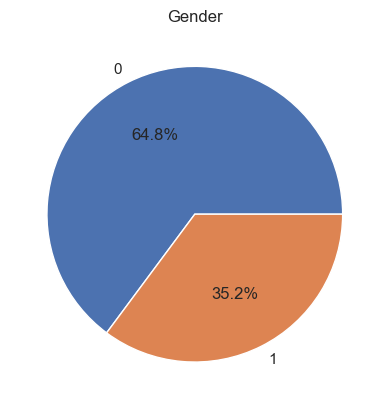

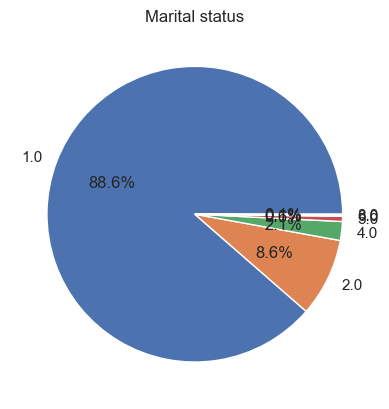

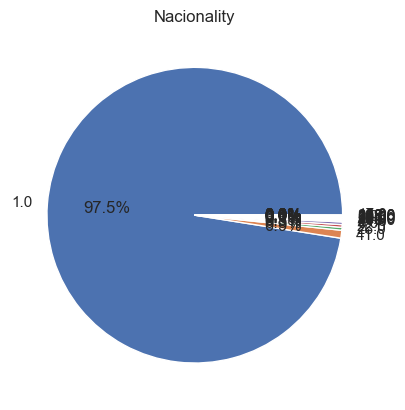

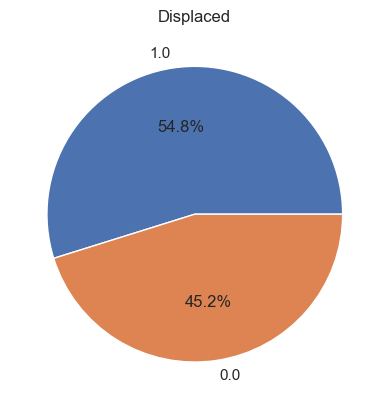

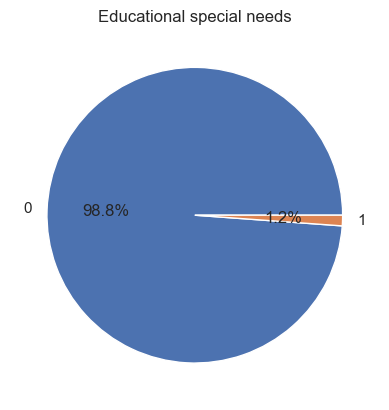

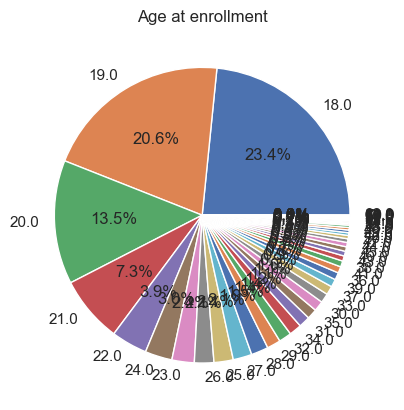

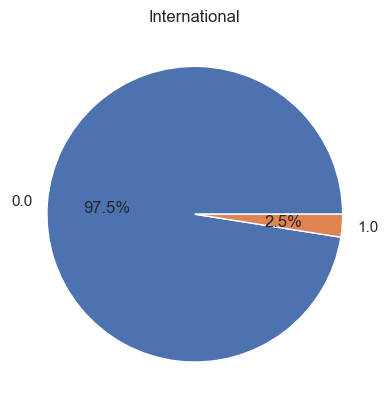

In [105]:
cols = ['Gender','Marital status', 'Nacionality', 'Displaced', 'Educational special needs', 'Age at enrollment', 'International']
for c in cols:
        df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
        plt.show()

Moving on to certain personal aspects that characterize the students, regarding gender, 64.8% are male students and the remaining 35.2% are female. 88.6% of them are single, 8.6% are married, and the rest fall into other marital statuses. Regarding nationality, 97.7% are of Portuguese nationality, making it evident that the data corresponds to that country, while the remainder corresponds to countries from different continents in smaller percentages. Regarding the displacement status of the students, 54.8% are in this situation, while the remaining percentage is not. Regarding the presence of special educational needs, 98.8% of the students do not present this condition, while the remaining 1.2% do. Regarding age at enrollment, a higher percentage is between 18 and 20 years old, which corresponds to the fact that they recently finished secondary education and entered their first higher education course, with 23.4% for 18 years old, 20.6% for 19, and 13.5% for 20. As ages increase, the percentages drop significantly. Regarding being an international student, as we have mentioned, 97% are not.

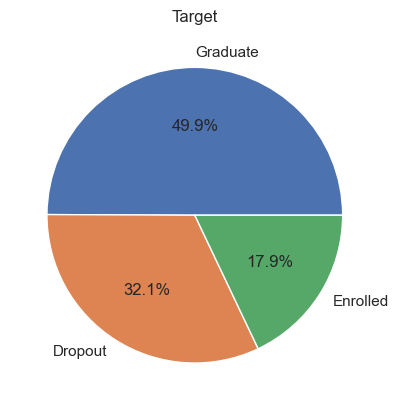

In [80]:
cols = ['Target']
for c in cols:
        df[c].value_counts().plot.pie(autopct='%1.1f%%', title=c, ylabel='')
        plt.show()

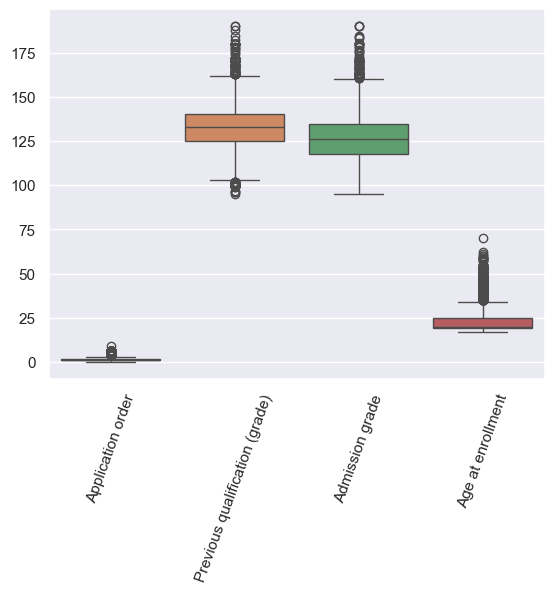

In [82]:
sns.boxplot(data=df[Enroll_Numerical_Features])
plt.xticks(rotation=70)
plt.show()

The enrollment age has a lot of outsiers of a higer age that the averge (corresponding to young people). The grades looks centraded, but wuith outsiders and the aplication order shows that most of the students selected the cours in one of their first preferences.

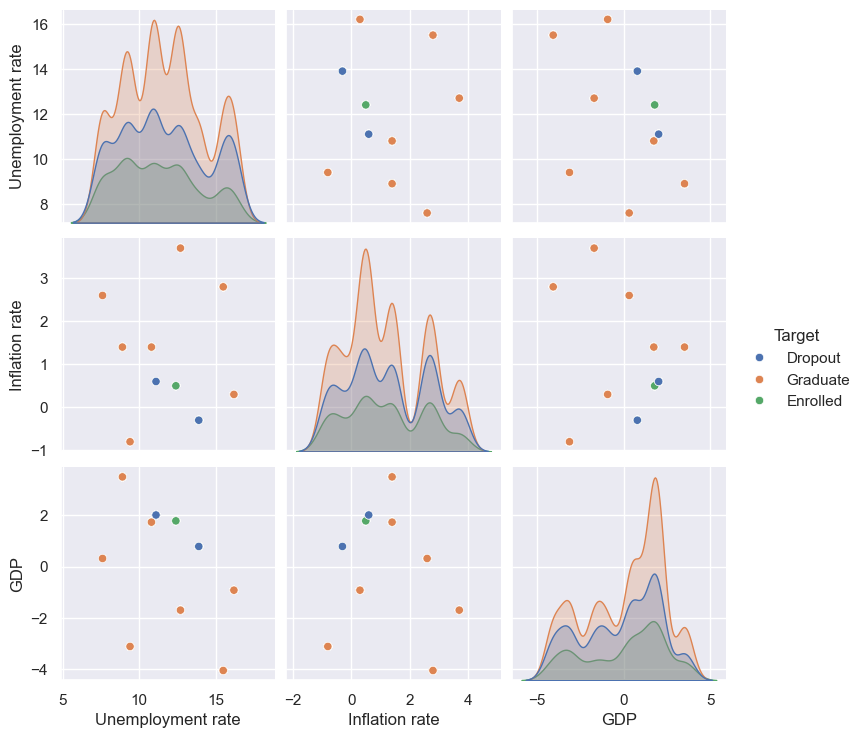

In [85]:
Economics_indicators=["Unemployment rate", "Inflation rate", "GDP"]
sns.pairplot(df,vars=Economics_indicators,hue="Target")
plt.show()

Is not claearly bisible relation betwuen macroeconomic indicators and the target variable

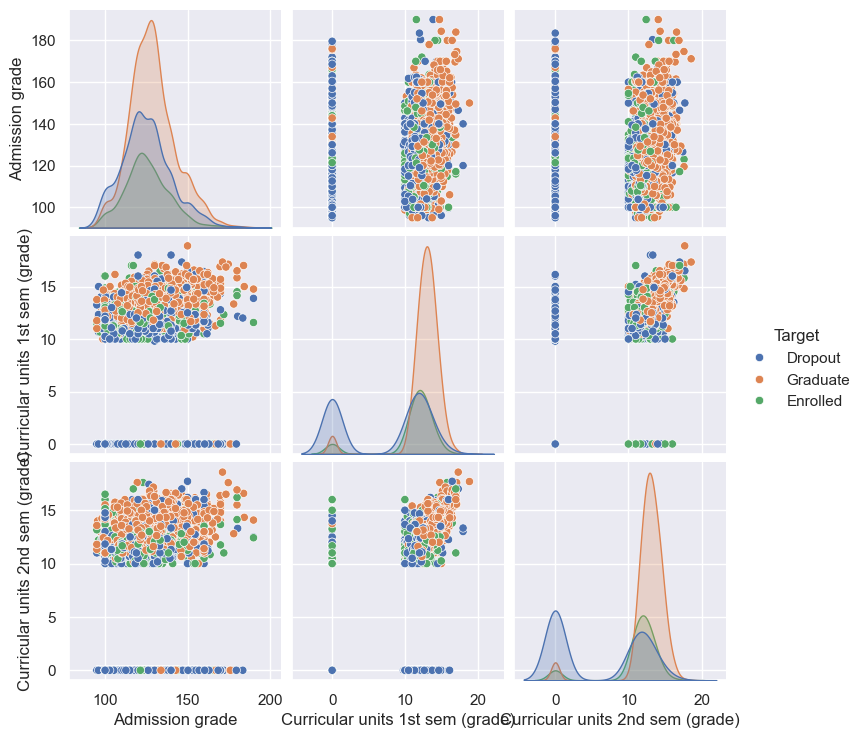

In [86]:
Grades=["Admission grade","Curricular units 1st sem (grade)","Curricular units 2nd sem (grade)"]
sns.pairplot(df,vars=Grades,hue="Target")
plt.show()  # por que miercale ya no muestra si antes mostrabaaaaaa

The shape of the distribution of the admition grade and the target variable shows the Dropout a litle it more to the lower grades and a litle bit more of graduates in the beter grades. Whith the curricular units of both semesters the graduate is clearly concentres in mor credits and the dropout is the lower number of units in the second semester, but equaly distributed in the firs one. The enrroled is concentreated as well in hier number of units in both semesters


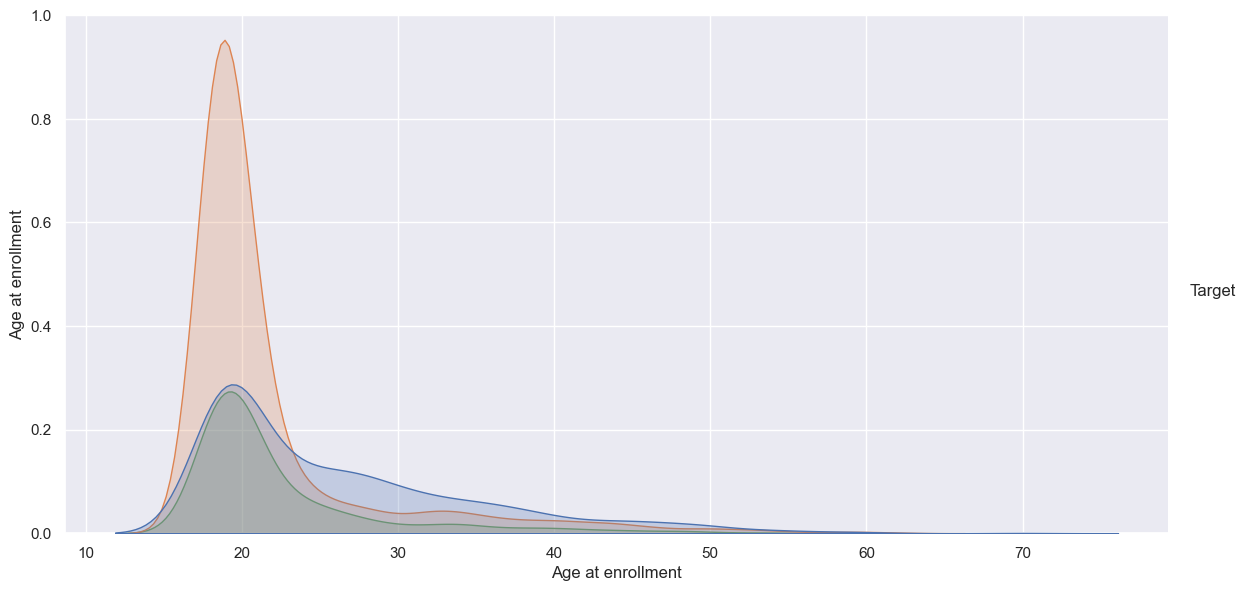

In [87]:
Age = ["Age at enrollment"]
sns.pairplot(df, vars=Age, hue="Target", height=6, aspect=2)
plt.show()

There is a clear concentration arround 20 years in all de categories of target, but the proportion of graduates is higer in the concentred age arround twenties and the droupout is significantly higer that the other two targets categories betwen arround 23 and 40 and mainteins a bit uper the otrer categories after fourtys

In [88]:
correlation = df['Previous qualification (grade)'].corr(df['Curricular units 1st sem (grade)'])
print(correlation)

0.05992537769204068


In [89]:
correlation = df['Previous qualification (grade)'].corr(df['Curricular units 2nd sem (grade)'])
print(correlation)

0.05378729176197286


In [90]:
correlation = df['Curricular units 1st sem (grade)'].corr(df['Curricular units 2nd sem (grade)'])
print(correlation) 

0.8371546968095427


The grades bethuen semesters are related, but not whit the previous cualification grades

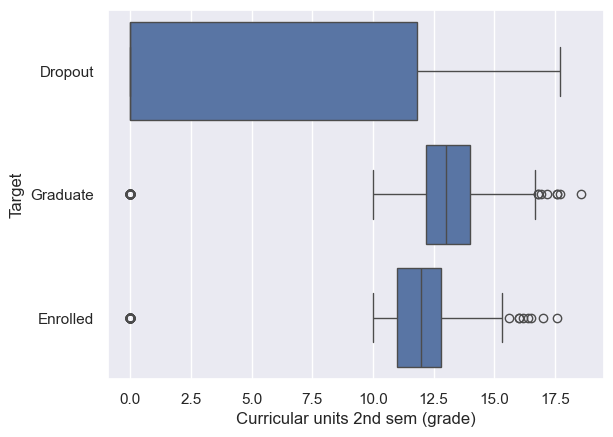

In [91]:
sns.boxplot(df, x="Curricular units 2nd sem (grade)", y="Target")
plt.show() 

There is relation betwen the grades and the graduation, beter grades are asociates with more chances of graduare and low, but some in a medium range also, are asociates whith drops out

In [92]:
df.rename(columns={"Curricular units 1st sem (credited)": "units 1st sem (credited)","Curricular units 1st sem (enrolled)": "units 1st sem (enrolled)","Curricular units 1st sem (evaluations)": "units 1st sem (evaluations)","Curricular units 1st sem (approved)": "units 1st sem (approved)","Curricular units 1st sem (grade)": "First sem grade","Curricular units 1st sem (without evaluations)": "units 1st sem (without evaluations)","Curricular units 2nd sem (credited)": "units 2nd sem (credited)","Curricular units 2nd sem (credited)": "units 2nd sem (credited)","Curricular units 2nd sem (enrolled)": "units 2nd sem (enrolled)","Curricular units 2nd sem (evaluations)": "units 2nd sem (evaluations)","Curricular units 2nd sem (approved)": "units 2nd sem (approved)","Curricular units 2nd sem (grade)": "Second sem grade","Curricular units 2nd sem (without evaluations)": "units 2nd sem (without evaluations)"}, inplace=True)

To identify other possible relationships that allow us to understand the variables and especially their connection with the target, I proceed to create a correlation heatmap. However, when plotting it, the long variable names hinder the visualization and clear understanding of the chart, so I proceed to rename them using shorter and easier-to-understand labels. Also, to see the relationship between the target variable and the other variables, we convert them to numerical format by encoding them.

In [109]:
label_encoder = LabelEncoder()
df['encoded_Target'] = label_encoder.fit_transform(df['Target'])
df

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,units 1st sem (credited),units 1st sem (enrolled),units 1st sem (evaluations),units 1st sem (approved),First sem grade,units 1st sem (without evaluations),units 2nd sem (credited),units 2nd sem (enrolled),units 2nd sem (evaluations),units 2nd sem (approved),Second sem grade,units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target,encoded_Target
0,1.0,17.0,5.0,171.0,1,1,122.0,1.0,19,12.0,5.0,9.0,127.3,1.0,0,0.0,1.0,1,0,20.0,0.0,0.0,0,0,0,0.000000,0,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
1,1.0,15.0,1.0,9254.0,1,1,160.0,1.0,1,3.0,3.0,3.0,142.5,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,6,6,14.000000,0,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,Graduate,2
2,1.0,1.0,5.0,9070.0,1,1,122.0,1.0,37,37.0,9.0,9.0,124.8,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,0,0,0.000000,0,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,Dropout,0
3,1.0,17.0,2.0,9773.0,1,1,122.0,1.0,38,37.0,5.0,3.0,119.6,1.0,0,0.0,1.0,0,0,20.0,0.0,0.0,6,8,6,13.428571,0,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate,2
4,2.0,39.0,1.0,8014.0,0,1,100.0,1.0,37,38.0,9.0,9.0,141.5,0.0,0,0.0,1.0,0,0,45.0,0.0,0.0,6,9,5,12.333333,0,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,Graduate,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1.0,1.0,6.0,9773.0,1,1,125.0,1.0,1,1.0,5.0,4.0,122.2,0.0,0,0.0,1.0,1,0,19.0,0.0,0.0,6,7,5,13.600000,0,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,Graduate,2
4420,1.0,1.0,2.0,9773.0,1,1,120.0,105.0,1,1.0,9.0,9.0,119.0,1.0,0,1.0,0.0,0,0,18.0,1.0,0.0,6,6,6,12.000000,0,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,Dropout,0
4421,1.0,1.0,1.0,9500.0,1,1,154.0,1.0,37,37.0,9.0,9.0,149.5,1.0,0,0.0,1.0,0,1,30.0,0.0,0.0,7,8,7,14.912500,0,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,Dropout,0
4422,1.0,1.0,1.0,9147.0,1,1,180.0,1.0,37,37.0,7.0,4.0,153.8,1.0,0,0.0,1.0,0,1,20.0,0.0,0.0,5,5,5,13.800000,0,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,Graduate,2


In [111]:
df.columns.tolist()

['Marital status',
 'Application mode',
 'Application order',
 'Course',
 'Daytime/evening attendance',
 'Previous qualification',
 'Previous qualification (grade)',
 'Nacionality',
 "Mother's qualification",
 "Father's qualification",
 "Mother's occupation",
 "Father's occupation",
 'Admission grade',
 'Displaced',
 'Educational special needs',
 'Debtor',
 'Tuition fees up to date',
 'Gender',
 'Scholarship holder',
 'Age at enrollment',
 'International',
 'units 1st sem (credited)',
 'units 1st sem (enrolled)',
 'units 1st sem (evaluations)',
 'units 1st sem (approved)',
 'First sem grade',
 'units 1st sem (without evaluations)',
 'units 2nd sem (credited)',
 'units 2nd sem (enrolled)',
 'units 2nd sem (evaluations)',
 'units 2nd sem (approved)',
 'Second sem grade',
 'units 2nd sem (without evaluations)',
 'Unemployment rate',
 'Inflation rate',
 'GDP',
 'Target',
 'encoded_Target']

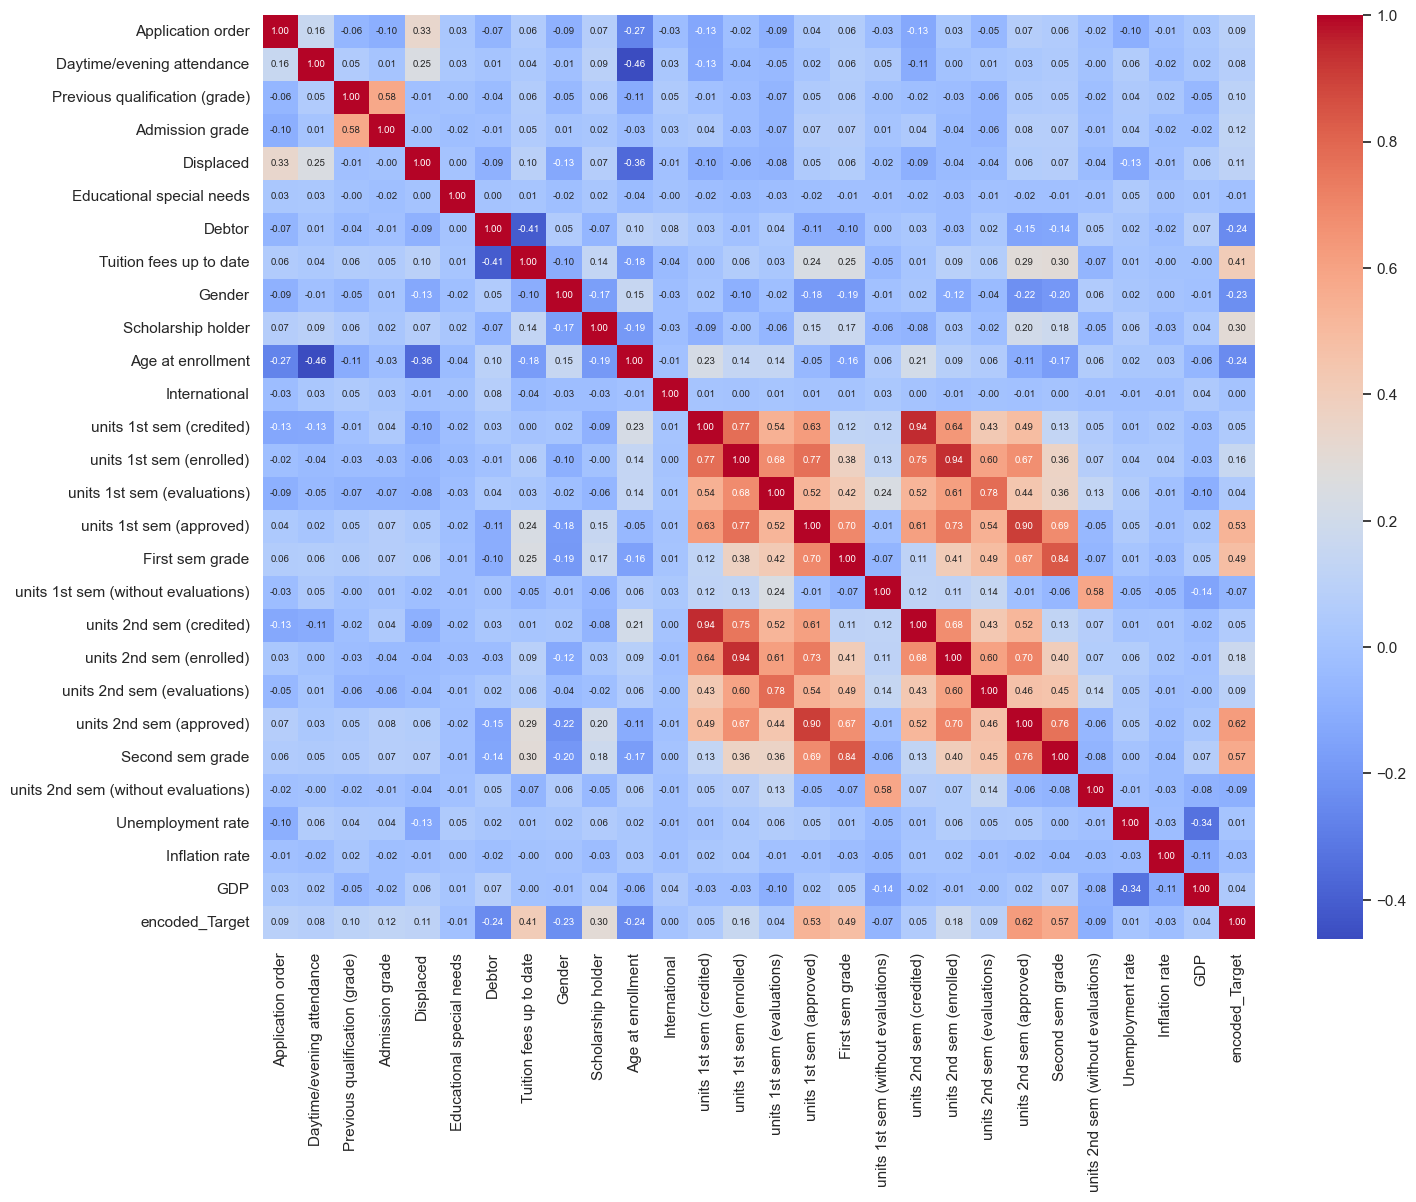

In [113]:
features = ['Application order', 'Daytime/evening attendance', 'Previous qualification (grade)', 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'units 1st sem (credited)', 'units 1st sem (enrolled)', 'units 1st sem (evaluations)', 'units 1st sem (approved)', 'First sem grade', 'units 1st sem (without evaluations)', 'units 2nd sem (credited)', 'units 2nd sem (enrolled)', 'units 2nd sem (evaluations)', 'units 2nd sem (approved)', 'Second sem grade', 'units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'encoded_Target']

plt.figure(figsize=(16, 12))
sns.heatmap(df[features].corr(), annot=True, fmt='.2f', annot_kws={"size": 7}, cmap='coolwarm')
plt.show()

In the correlation matrix, we add the dichotomous and ordinal variables, as well as the target variable. While the target variable cannot be evaluated with a direct correlation, it's included to see if there's any indication of a relationship. We see there is a small relationship with the tuition. We see there is a relationship of 0.53 with the units approved in the semester and of 0.49 with the grades of the first semester, and this relationship tends to increase in the second semester with a 0.62 with the units approved and a 0.57 with the grades. While we cannot take these numbers purely with a correlation, as it is a categorical variable, we do see that it appears to be related, which makes sense with the grades and the possibility of finishing the courses on time. Likewise, we see that there is a relationship between the units, time, and grades between the semesters with a strong relationship, but this can also have to do with the units often being quite similar for all students, so there is not a large variance within these variables. There is also a relationship between the age of enrollment and the tendency to be late, but we believe this can also be due to a large concentration in certain ages and a large concentration late. There are also relationships, less strong but negative in this case, between the unemployment rate and the GDP, which makes sense as both are related macroeconomic indicators. Beyond that, there are no significant relationships that we can see.

The "Curse of Dimensionality" is the group of problems that emerge when we have a bigger group of dimensions or features. Intuitively, more information looks like a good thing, but it presents some problems, for example, the Data Sparsity. So if we have one feature we can think of it like a line, if we have two dimensions like a square, and three dimensions as a cube. If we have the same amount of observations in a line, in a square, or in a cube, the dispersion will be a lot more in the square than in the line and even more in the cube. So if we are trying to get "the shape," it could be difficult in a cube with a few observations and a lot of empty space, and we cannot get more observations. That exponential growth of space happens every time we add a dimension, in the same way that the transit from 2D to 3D is exponentially bigger, not just a bit more. With that much space, the program will try to get shapes and patterns of the data in suboptimal conditions and can make an overfitting. This problem is when the system has not enough observations to see real relations between a lot of variables, so it makes false connections that just could make sense in the data set. Let's say we take 100 people and we ask them 100 questions about favorite things (color, food, etc.), because the system doesn't see any pattern between the people who like purple color, which happens to be 7, the system continues looking, and with just 7 observations it is easy that by chance 3 of them like Chinese food. So the system will establish that purple and Chinese food are related, something that, of course, just happens by chance in that data set. Although this dataset does not contain an immense number of columns, 37 is still a large number, and the possibility of reducing them helps address the challenges associated with having so many dimensions.

Next, we will apply PCA to determine the minimum number of variables. To do this, we will start by creating a copy of the cleaned dataframe and removing any NaN values; although we had previously attempted to remove them, the PCA process still failed because it continued to treat null valuesas valid entries—preventing certain inputs from being processed as numbers and thereby blocking the PCA. We will therefore address this, and subsequently remove the target column, which is categorical.

In [95]:
df_sin_nan = df.dropna().copy()

In [96]:
df_sin_nan.drop(columns=['Target'], inplace=True)

In [97]:
df_sin_nan

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,units 1st sem (credited),units 1st sem (enrolled),units 1st sem (evaluations),units 1st sem (approved),First sem grade,units 1st sem (without evaluations),units 2nd sem (credited),units 2nd sem (enrolled),units 2nd sem (evaluations),units 2nd sem (approved),Second sem grade,units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,encoded_Target
0,1.0,17.0,5.0,171.0,1,1,122.0,1.0,19,12.0,5.0,9.0,127.3,1.0,0,0.0,1.0,1,0,20.0,0.0,0.0,0,0,0,0.000000,0,0,0.0,0,0,0.000000,0,10.8,1.4,1.74,0
1,1.0,15.0,1.0,9254.0,1,1,160.0,1.0,1,3.0,3.0,3.0,142.5,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,6,6,14.000000,0,0,6.0,6,6,13.666667,0,13.9,-0.3,0.79,2
2,1.0,1.0,5.0,9070.0,1,1,122.0,1.0,37,37.0,9.0,9.0,124.8,1.0,0,0.0,0.0,1,0,19.0,0.0,0.0,6,0,0,0.000000,0,0,6.0,0,0,0.000000,0,10.8,1.4,1.74,0
3,1.0,17.0,2.0,9773.0,1,1,122.0,1.0,38,37.0,5.0,3.0,119.6,1.0,0,0.0,1.0,0,0,20.0,0.0,0.0,6,8,6,13.428571,0,0,6.0,10,5,12.400000,0,9.4,-0.8,-3.12,2
4,2.0,39.0,1.0,8014.0,0,1,100.0,1.0,37,38.0,9.0,9.0,141.5,0.0,0,0.0,1.0,0,0,45.0,0.0,0.0,6,9,5,12.333333,0,0,6.0,6,6,13.000000,0,13.9,-0.3,0.79,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4419,1.0,1.0,6.0,9773.0,1,1,125.0,1.0,1,1.0,5.0,4.0,122.2,0.0,0,0.0,1.0,1,0,19.0,0.0,0.0,6,7,5,13.600000,0,0,6.0,8,5,12.666667,0,15.5,2.8,-4.06,2
4420,1.0,1.0,2.0,9773.0,1,1,120.0,105.0,1,1.0,9.0,9.0,119.0,1.0,0,1.0,0.0,0,0,18.0,1.0,0.0,6,6,6,12.000000,0,0,6.0,6,2,11.000000,0,11.1,0.6,2.02,0
4421,1.0,1.0,1.0,9500.0,1,1,154.0,1.0,37,37.0,9.0,9.0,149.5,1.0,0,0.0,1.0,0,1,30.0,0.0,0.0,7,8,7,14.912500,0,0,8.0,9,1,13.500000,0,13.9,-0.3,0.79,0
4422,1.0,1.0,1.0,9147.0,1,1,180.0,1.0,37,37.0,7.0,4.0,153.8,1.0,0,0.0,1.0,0,1,20.0,0.0,0.0,5,5,5,13.800000,0,0,5.0,6,5,12.000000,0,9.4,-0.8,-3.12,2


In [121]:
X = df_sin_nan.drop(columns=['encoded_Target'])
y = df_sin_nan['encoded_Target']

In [122]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

I tried using a Robust Scaler because there were some outliers. While this significantly reduced the number of required components—down to 23—an examination of the variable weights revealed an issue: in the first component (which naturally captured a substantial portion of the variance), a single variable—"previous rating"—accounted for over 99% of that component. This suggests that the variable may have had very little variance—perhaps because the responses were coded in such a way that many entries shared the same "previous rating." In any case, if a component is essentially just reproducing one of the original variables, it fails to achieve the intended purpose of PCA; therefore, I discarded this scaling method.

In [100]:
pca = PCA(n_components=33) 
pca.fit(X_scaled) 
X_pca = pca.transform(X_scaled)
print(X.shape) 
print(X_pca.shape)

(4400, 36)
(4400, 33)


In [101]:
print(pca.explained_variance_ratio_)

[0.17663303 0.09888263 0.05866246 0.05593033 0.05265138 0.0466265
 0.044209   0.04265651 0.03589125 0.03436094 0.03026428 0.02809387
 0.0274222  0.02594253 0.0242548  0.02258359 0.02199023 0.02024137
 0.01768284 0.01631467 0.01558317 0.01479319 0.01288022 0.01259487
 0.01148032 0.01067023 0.00883117 0.00664753 0.00580721 0.00529244
 0.0047051  0.00289977 0.00253947]


In [102]:
total_var = pca.explained_variance_ratio_.sum() * 100
print(X_pca, total_var)

[[-6.09901322 -0.30423445 -1.4163524  ... -0.02270483 -0.18351696
   0.02834352]
 [-0.24981143 -1.10348397 -1.85470757 ... -0.05172857 -0.08422774
   0.03394815]
 [-3.9525186   0.43895356  0.01768408 ...  0.00756848  0.29183197
  -0.16127821]
 ...
 [ 0.69964897 -1.13963383  0.5750306  ...  0.76807799  0.787084
  -0.66153783]
 [-0.50759115 -1.9984708   0.03428041 ...  0.20186756 -0.02180115
   0.1252812 ]
 [ 0.14654203 -1.06736485 -0.86040303 ... -0.30743923 -0.27333125
   0.00889929]] 99.60191436479153


In [103]:
loadings = pd.DataFrame(
    pca.components_[:3].T, index=X.columns, columns=[f"PC{i+1}" for i in range(3)])
print(loadings)

                                          PC1       PC2       PC3
Marital status                       0.015522  0.250318  0.151367
Application mode                     0.057585  0.358454 -0.012234
Application order                   -0.014265 -0.225476  0.041374
Course                               0.131720 -0.038935  0.213210
Daytime/evening attendance          -0.017316 -0.249509 -0.149623
Previous qualification               0.044912  0.171242 -0.101498
Previous qualification (grade)      -0.000597 -0.065059 -0.160794
Nacionality                         -0.009838 -0.009188 -0.113289
Mother's qualification               0.016740  0.160866  0.304417
Father's qualification               0.017227  0.116247  0.299157
Mother's occupation                 -0.003818  0.075597  0.422102
Father's occupation                 -0.006100  0.063666  0.429215
Admission grade                      0.008509 -0.033375 -0.184285
Displaced                           -0.018308 -0.260481 -0.035921
Educationa

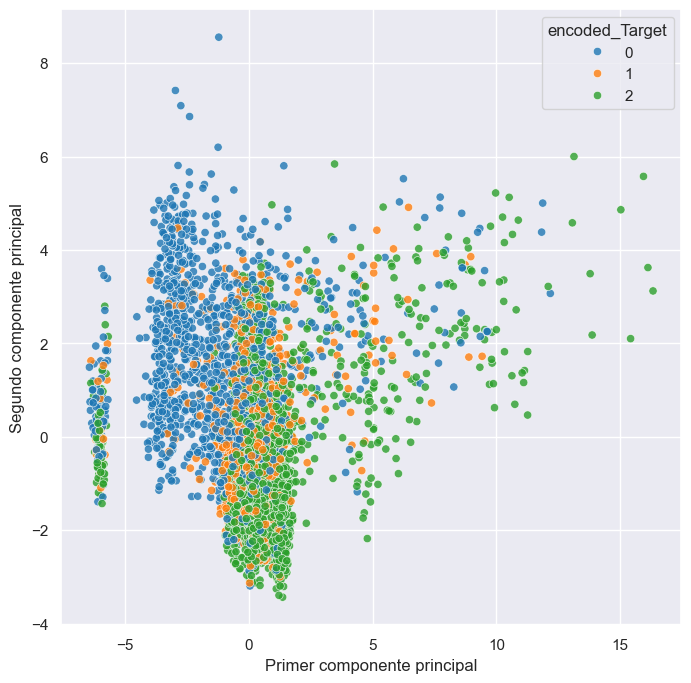

In [104]:
plt.figure(figsize=(8, 8))
sns.scatterplot(
    x=X_pca[:, 0], 
    y=X_pca[:, 1], 
    hue=y, 
    palette='tab10', 
    alpha=0.8
)

plt.xlabel("Primer componente principal")
plt.ylabel("Segundo componente principal")
plt.legend(title='encoded_Target', loc="best")
plt.show()

To do the PCA, I first tried with a few components, starting with three. But after looking at the explained variance ratio and seeing that the first few components concentrated so little of the variance, I realized I needed to do the regular approach. So I did the opposite operation, starting from 36 columns and reducing them until, by looking at the cumulative sum of the variances, I reached the number closest to just over 99.5%, which ended up being 33 components.
I'm having a hard time understanding why it was reduced by so little when in class we worked with other datasets that reduced down much more, but after doing it multiple times and changing things around, I saw that apparently it was just supposed to be that way.
Something that helped me realize when I had scaled or standardized things poorly—even though that had allowed me to have fewer components yielding the same preserved variance sum—was that when checking which columns the component concentrated on, there was one column concentrating 90% of the first component. So there was an error because the objective wasn't being achieved.
That also helped me see where the different components were taking their percentages from, and to better understand this type of methodology.
Then I plotted it to see the distribution, but since it's a 2D image, I could only select the first two components. While a certain distribution is visible, it's not very clear. However, understanding that those components concentrate less than 30% of the variance, I wouldn't expect a clearer separation than what's seen in the image, with the blue, orange, and green dots heavily overlapping each other.

In conclusion, the project consisted of the analysis of a dataset on higher education students with 37 columns and 4,424 rows. The main objective was to examine the students' profile, identify correlations with their final status (graduated, dropped out, or enrolled), and apply Principal Component Analysis (PCA).

During the cleaning phase, data quality issues were detected, such as unrecognized null values, incorrect data types (numeric variables read as text due to typos like "five", "UnKnown", or "Na"), and the need to standardize names to avoid system conflicts. The exploratory and statistical analysis allowed for conclusions regarding the students' characteristics, finding that most students were young with an average age of 23.3 years, predominantly of Portuguese nationality, single, and without special educational needs, with nearly 84% having completed secondary education. Regarding choice and preference, 68.4% of the students chose the course as their first preference, which suggested a high level of initial motivation, while in the family environment, the parents' education level tended to be basic or secondary, frequently falling into unskilled worker categories, indicating that many students were achieving higher educational levels than their parents. Regarding the financial situation, 88.6% had no debts with the institution, 88.1% had their tuition up to date, and 75.2% had some type of scholarship. Regarding the relationships with performance and dropout, grades and passed units in the first and second semesters showed a strong correlation with graduation, with better academic results associated with a higher probability of success, while lower values coincided with dropping out; conversely, macroeconomic variables showed no obvious or direct relationship with the students' final status.

Finally, when applying dimensionality reduction via PCA, it was identified that to preserve more than 99.5% of the variance, 33 components were required, indicating that the reduction was limited due to the nature and variance of the original variables. Furthermore, when plotting the first two components, a high overlap was observed between the student categories, reflecting that the initial components concentrated a low percentage of the total variance.